# IncepTIS — quick demonstration

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HaLU-9000/IncepTIS/blob/main/demo.ipynb)

**IncepTIS** predicts position-resolved translation-initiation signals along a transcript under a normal and
a stress condition. It is an NTv3 nucleotide-language-model backbone with an attention U-Net head, trained
on the TISCA2 dataset of translation-initiation sites. **IncepTIS-Evolve** turns those predictions into a
design tool: it searches sequences that initiate translation at chosen positions under one condition and not
the other.

> **This notebook does not run the published model.** The trained weights and the TISCA2 data are not
> released while the work is a preprint, so the notebook leaves the NTv3 backbone out entirely. What runs
> here is the attention U-Net alone, written out in the notebook and trained from scratch on a synthetic data
> set that the notebook also generates. It shows the shape of the workflow and reproduces neither the
> architecture nor the behaviour of the published model. The commands of the real pipeline, backbone
> included, are in the README.

The five steps:

1. **The data** — a synthetic set of transcripts with one start codon per condition.
2. **The model** — the attention U-Net, defined here.
3. **Training** — one fold, with the two loss terms of the published configuration.
4. **Prediction** — per-base scores for a held-out sequence, next to the targets.
5. **Design** — IncepTIS-Evolve on a four-site construct, scored by the model trained here, with the search
   animated.

> **The data are artificial.** The two conditions come from a motif rule, not from an experiment, so no score
> or sequence produced here carries biological meaning.

A GPU runtime is worth picking: the training cell is seconds of GPU time but minutes of CPU time, and
everything else is light. On CPU, lower `EPOCHS` in that cell. Each cell builds on the ones above it, so
run them in order.

## 1. Setup

Nothing needs to be installed: the notebook uses torch, numpy, pandas, scikit-learn and matplotlib, which
Colab already has. The repository is cloned for its `inceptis_evolve` package, used in the design section.
No Hugging Face account and no model download are involved.

In [1]:
import sys

import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("python", sys.version.split()[0], "| torch", torch.__version__, "| device", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))

python 3.13.16 | torch 2.11.0+cu130 | device cuda
Tesla T4


In [2]:

# ============================================================
# Reproducibility settings
# ============================================================

import os

SEED = 524

# Set before importing torch / initializing CUDA
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

# Optional: reduce numerical differences from TF32
os.environ["NVIDIA_TF32_OVERRIDE"] = "0"

import random
import numpy as np
import torch


def seed_everything_strict(seed=524):
    # Python
    random.seed(seed)

    # NumPy global RNG
    np.random.seed(seed)

    # PyTorch CPU
    torch.manual_seed(seed)

    # PyTorch CUDA (all GPUs)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # cuDNN
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.enabled = True

    # Disable TF32
    if hasattr(torch.backends.cuda.matmul, "allow_tf32"):
        torch.backends.cuda.matmul.allow_tf32 = False

    if hasattr(torch.backends.cudnn, "allow_tf32"):
        torch.backends.cudnn.allow_tf32 = False

    # Force deterministic PyTorch algorithms
    torch.use_deterministic_algorithms(True)

    # Disable reduced-precision reductions when supported
    if torch.cuda.is_available():
        if hasattr(torch.backends.cuda.matmul, "allow_fp16_reduced_precision_reduction"):
            torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False

        if hasattr(torch.backends.cuda.matmul, "allow_bf16_reduced_precision_reduction"):
            torch.backends.cuda.matmul.allow_bf16_reduced_precision_reduction = False

    # Fixed generators for explicit RNG usage
    numpy_rng = np.random.default_rng(seed)

    torch_generator = torch.Generator()
    torch_generator.manual_seed(seed)

    return numpy_rng, torch_generator


numpy_rng, torch_generator = seed_everything_strict(SEED)

print(f"Seed: {SEED}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA: {torch.cuda.is_available()}")
print(f"Deterministic algorithms: {torch.are_deterministic_algorithms_enabled()}")


Seed: 524
PyTorch: 2.11.0+cu130
CUDA: True
Deterministic algorithms: True


In [3]:
import os
import pathlib
import sys

IN_COLAB = "google.colab" in sys.modules
REPO = pathlib.Path("/content/IncepTIS") if IN_COLAB else pathlib.Path.cwd()

if IN_COLAB and not REPO.exists():
    !git clone --depth 1 https://github.com/HaLU-9000/IncepTIS.git "{REPO}"

os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print("repository:", REPO)

repository: /content/IncepTIS


In [4]:
# One figure style for the whole notebook. The two conditions keep the same two colours everywhere.
import matplotlib as mpl
import matplotlib.pyplot as plt

NORMAL, STRESS = "#0072B2", "#D55E00"
INK, MUTED, GRID = "#3f4248", "#6b6f76", "#d7d7d4"

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "grid.alpha": 0.7,
    "xtick.color": INK,
    "ytick.color": INK,
    "text.color": INK,
    "font.size": 9,
    "axes.titlesize": 10,
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

## 2. The demonstration data

The next cell writes the data set to `outputs/demo_data/`: 200 deterministic 256-nt sequences, each carrying
two initiation sites, one per condition.

- The **normal** site is an AUG inside a TISU element, `SAASATGGCGGC`, where each `S` is drawn as C or G.
- The **stress** site is a bare CUG with nothing around it, a near-cognate start.
- Both sites are in the reading frame of position 1, so every initiation site in the set is a multiple of
  three apart from every other one. The AUG falls between positions 40 and 70, the CUG between 160 and 190.
- Each of the two codons occurs exactly once in the whole sequence: the generator rewrites stray ATG and CTG
  triplets elsewhere, so neither site is ambiguous.

Every sequence is written twice, once per condition. Condition 0 centres a unit-height exponential peak
(`exp(-0.2 × distance)`) on the AUG, condition 1 centres one on the CUG. Gaussian noise (sigma 0.05) is added
before the values are clipped to [0, 1]. The 400 files use the eight-column IncepTIS training-data format
described in the README. Nothing is committed to the repository, so the size of the set is just the
`SEQUENCE_COUNT` line.

Two of the eight columns are targets. `cosine similarity` is the regression target; `peak_mask` holds the
codon of the initiation site at every position whose target exceeds 0.2 and `False` elsewhere, and is the
target of the second loss term. The rest are carried along.

In [5]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import KFold

SEQUENCE_LENGTH = 256
TISU, TISU_AUG_OFFSET = "SAASATGGCGGC", 4        # TISU element; S is C or G, AUG at offset 4
STRESS_CODON = "CTG"                             # bare near-cognate CUG start
START_CODONS = ("ATG", STRESS_CODON)
AUG_WINDOW, CUG_WINDOW = (40, 70), (160, 190)    # inclusive 1-based windows for the start position
SEQUENCE_COUNT, SEED, ALPHA, NOISE_SIGMA = 200, 524, 0.2, 0.05
PEAK_MASK_THRESHOLD, NON_PEAK_MAXIMUM = 0.2, 1.0 - 1e-6
BASES, STRONG = np.array(list("ACGT")), np.array(list("CG"))
DEMO_DATA = REPO / "outputs" / "demo_data"


def in_frame_starts(window):
    '''The start positions inside the window that share the reading frame of position 1.'''
    start, stop = window
    return np.arange(start + (1 - start) % 3, stop + 1, 3)


AUG_STARTS, CUG_STARTS = in_frame_starts(AUG_WINDOW), in_frame_starts(CUG_WINDOW)


def make_sequence(rng):
    '''A sequence whose only ATG is the TISU one and whose only CTG is the bare stress site.'''
    aug, cug = int(rng.choice(AUG_STARTS)), int(rng.choice(CUG_STARTS))
    tisu = "".join(str(rng.choice(STRONG)) if base == "S" else base for base in TISU)
    tisu_slice = slice(aug - 1 - TISU_AUG_OFFSET, aug - 1 - TISU_AUG_OFFSET + len(tisu))
    frozen = set(range(tisu_slice.start, tisu_slice.stop)) | {cug - 1, cug, cug + 1}
    while True:
        bases = rng.choice(BASES, SEQUENCE_LENGTH).tolist()
        bases[tisu_slice] = list(tisu)
        bases[cug - 1:cug + 2] = list(STRESS_CODON)
        for _ in range(500):
            sequence = "".join(bases)
            unwanted = [index for index in range(SEQUENCE_LENGTH - 2)
                        if sequence[index:index + 3] in START_CODONS
                        and index not in (aug - 1, cug - 1)]
            if not unwanted:
                return sequence, aug, cug
            for index in unwanted:        # rewrite one free base of each stray start codon
                for position in (index + 2, index + 1, index):
                    if position not in frozen:
                        bases[position] = str(rng.choice(BASES))
                        break


def simulated_peak(rng, site):
    '''A unit-height exponential peak on the site, over clipped Gaussian background noise.'''
    distance = np.abs(np.arange(SEQUENCE_LENGTH) - (site - 1))
    values = np.clip(np.exp(-ALPHA * distance) + rng.normal(0.0, NOISE_SIGMA, SEQUENCE_LENGTH),
                     0.0, NON_PEAK_MAXIMUM)
    values[site - 1] = 1.0
    return values


def write_condition(path, sequence, condition, site, values):
    '''One training file in the eight-column IncepTIS format.'''
    codon = sequence[site - 1:site + 2]
    pd.DataFrame({
        "position": range(SEQUENCE_LENGTH),
        "base": list(sequence),
        "codon": [sequence[index:index + 3] for index in range(SEQUENCE_LENGTH)],
        "condition": condition,
        "cosine similarity": values,
        "normalized_similarity": values,
        "length coverage": 1,
        "peak_mask": [codon if value > PEAK_MASK_THRESHOLD else "False" for value in values],
    }).to_csv(path, index=False)


sequence_rng, signal_rng = np.random.default_rng(SEED), np.random.default_rng(SEED + 1)
records = [(f"demo{index:03d}", *make_sequence(sequence_rng)) for index in range(SEQUENCE_COUNT)]

training_dir = DEMO_DATA / "training"
training_dir.mkdir(parents=True, exist_ok=True)
for stale in training_dir.glob("*.txt"):
    stale.unlink()

targets = {}
for sequence_id, sequence, aug, cug in records:
    targets[sequence_id] = [simulated_peak(signal_rng, aug), simulated_peak(signal_rng, cug)]
    for condition, site in enumerate((aug, cug)):
        write_condition(training_dir / f"{sequence_id}_condition{condition}_rep0.txt",
                        sequence, condition, site, targets[sequence_id][condition])

manifest = pd.DataFrame([{"sequence_id": sequence_id, "aug_1based": aug, "cug_1based": cug}
                         for sequence_id, _, aug, cug in records])
sequences = {sequence_id: sequence for sequence_id, sequence, _, _ in records}

print(f"{len(records)} sequences of {SEQUENCE_LENGTH} nt"
      f" in {len(list(training_dir.glob('*.txt')))} files under {training_dir}")
display(manifest.head(3))
display(pd.read_csv(training_dir / "demo000_condition0_rep0.txt").head(3))

200 sequences of 256 nt in 400 files under /content/IncepTIS/outputs/demo_data/training


,sequence_id,aug_1based,cug_1based
0,demo000,40,163
1,demo001,58,178
2,demo002,61,175


,position,base,codon,condition,cosine similarity,normalized_similarity,length coverage,peak_mask
0,0,G,GCC,0,0.000000,0.000000,1,False
1,1,C,CCA,0,0.019584,0.019584,1,False
2,2,C,CAT,0,0.009246,0.009246,1,False


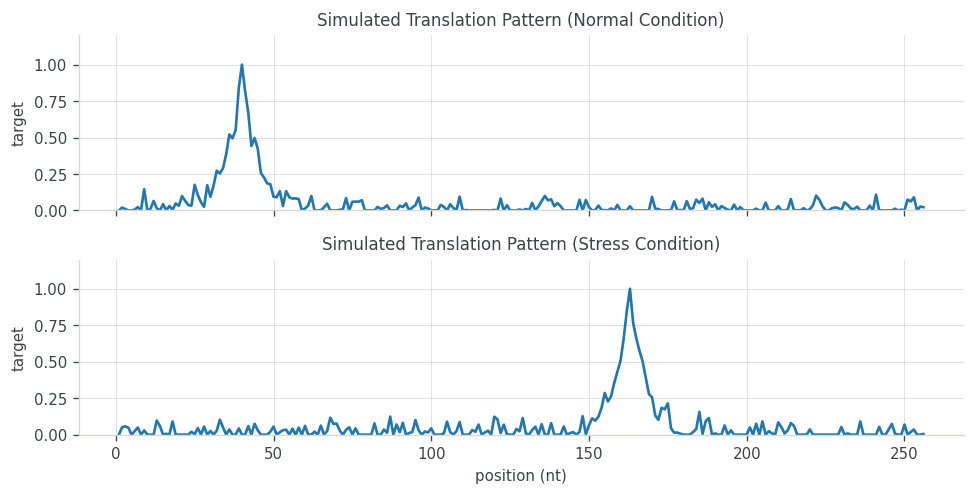

In [6]:
# One sequence, both conditions: the peak moves from the TISU AUG to the bare CUG.
def sites_of(sequence_id):
    row = manifest.set_index("sequence_id").loc[sequence_id]
    return int(row["aug_1based"]), int(row["cug_1based"])

example_id = "demo000"
example_sites = sites_of(example_id)
position = np.arange(1, SEQUENCE_LENGTH + 1)

fig, axes = plt.subplots(2, 1, figsize=(8.2, 4.2), sharex=True, sharey=True)

for ax, condition, name in [
    (axes[0], 0, "Simulated Translation Pattern (Normal Condition)"),
    (axes[1], 1, "Simulated Translation Pattern (Stress Condition)")
]:
    values = targets[example_id][condition]
    ax.plot(position, values, color="tab:blue")
    ax.set_ylim(0, 1.2)
    ax.set_ylabel("target")
    ax.set_title(name)

axes[1].set_xlabel("position (nt)")
fig.tight_layout()
plt.show()

## 3. The model

The published model reads a transcript with the NTv3-100M backbone and puts an attention U-Net on its last
hidden state, with the condition appended as an extra channel:

```text
 sequence   A C G T A C ...        one token per base, context 32,768
                 |
      [ NTv3-100M backbone ]       6 transformer layers over a convolutional stem
                 |
          768 values per base
                 |
                 +---- condition channel  (0 = normal, 1 = stress)
                 |
          769 channels per base
                 |
      [ 1-D attention U-Net ]
          enc  64 ch ------------- gate ------------+
            | pool /2                               |
          enc 128 ch -------- gate ------+          |
            | pool /2                    |          |
          enc 256 ch -- gate --+         |          |
            | pool /2          |         |          |
          bottleneck 512 ch    |         |          |
            | upsample x2 -----+         |          |
          dec 256 ch                     |          |
            | upsample x2 ---------------+          |
          dec 128 ch                                |
            | upsample x2 --------------------------+
          dec  64 ch
                 |
                 +--> 1x1 conv, sigmoid        -> score per base, per condition   (MSE, weight 0.5)
                 +--> 1x1 conv - threshold     -> logit per base, per condition   (BCE, weight 0.5)
```

This notebook keeps that U-Net and drops the backbone. The four bases go in as one-hot channels and the
condition as a fifth; from the first encoder stage down it is the same stack:

```text
 sequence   A C G T A C ...        one-hot, four channels
                 |
                 +---- condition channel  (0 = normal, 1 = stress)
                 |
            5 channels per base
                 |
      [ 1-D attention U-Net ]      the stack above, 64 / 128 / 256, bottleneck 512
                 |
                 +--> 1x1 conv, sigmoid        -> score per base, per condition   (MSE, weight 0.5)
                 +--> 1x1 conv - threshold     -> logit per base, per condition   (BCE, weight 0.5)
```

Two further differences from the published configuration: there is no 65-class codon head, which carries
weight zero there, and every sequence here is the same length, so the masking the U-Net applies to padded
positions never comes into play.

In [7]:
from torch import nn


class AttentionGate(nn.Module):
    '''Lets the decoder signal gate the encoder features it is about to be joined with.'''

    def __init__(self, channels, intermediate, dropout=0.1):
        super().__init__()
        self.from_decoder = nn.Sequential(nn.Conv1d(channels, intermediate, 1),
                                          nn.BatchNorm1d(intermediate))
        self.from_encoder = nn.Sequential(nn.Conv1d(channels, intermediate, 1),
                                          nn.BatchNorm1d(intermediate))
        self.attention = nn.Sequential(nn.Conv1d(intermediate, 1, 1), nn.BatchNorm1d(1), nn.Sigmoid())
        self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, decoder, encoder):
        gate = self.dropout(self.relu(self.from_decoder(decoder) + self.from_encoder(encoder)))
        return encoder * self.attention(gate)


class ConvBlock(nn.Module):
    '''Convolution, batch norm, ReLU and dropout at one resolution.'''

    def __init__(self, in_channels, out_channels, kernel=3, padding=1, dropout=0.1):
        super().__init__()
        self.conv = nn.Conv1d(in_channels, out_channels, kernel, padding=padding)
        self.norm = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.relu(self.norm(self.conv(x))))


class AttentionUNet1D(nn.Module):
    '''1-D U-Net with attention gates on the skip connections, one score per base.'''

    def __init__(self, input_features=5, num_features=64, num_layers=3, dropout=0.1,
                 init_threshold=0.2):
        super().__init__()
        self.num_layers = num_layers
        self.encoders = nn.ModuleList()
        incoming = input_features
        for level in range(num_layers):
            outgoing = num_features * 2 ** level
            kernel, padding = (7, 3) if level == 0 else (3, 1)
            self.encoders.append(ConvBlock(incoming, outgoing, kernel, padding, dropout))
            incoming = outgoing
        self.pool = nn.MaxPool1d(2)
        bottleneck = num_features * 2 ** num_layers
        self.bottleneck = ConvBlock(num_features * 2 ** (num_layers - 1), bottleneck, dropout=dropout)
        self.gates, self.upsamples, self.decoders = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        for step in range(num_layers):
            width = num_features * 2 ** (num_layers - step - 1)
            self.gates.append(AttentionGate(width, max(width // 2, num_features // 2), dropout))
            self.upsamples.append(nn.Sequential(
                nn.Upsample(scale_factor=2, mode="nearest"),
                nn.Conv1d(bottleneck if step == 0 else width * 2, width, 3, padding=1)))
            self.decoders.append(ConvBlock(width, width, dropout=dropout))
        self.score_conv = nn.Conv1d(num_features, 1, 1)
        self.logit_threshold = nn.Parameter(torch.logit(torch.tensor(init_threshold)))

    def forward(self, x):
        '''x is [batch, length, channels]; returns one value per base for each output.'''
        current = x.permute(0, 2, 1)
        encoded = []
        for level, encoder in enumerate(self.encoders):
            current = encoder(current)
            encoded.append(current)
            if level < self.num_layers - 1:
                current = self.pool(current)
        current = self.bottleneck(self.pool(encoded[-1]))
        for step in range(self.num_layers):
            current = self.upsamples[step](current)
            skip = encoded[self.num_layers - step - 1]
            current = self.decoders[step](current + self.gates[step](current, skip))
        logits = self.score_conv(current).permute(0, 2, 1).squeeze(-1)
        return {"regression": torch.sigmoid(logits), "binarization": logits - self.logit_threshold}


torch.manual_seed(524)
model = AttentionUNet1D().to(DEVICE)
print(f"{sum(parameter.numel() for parameter in model.parameters()):,} parameters on {DEVICE}")

1,384,811 parameters on cuda


## 4. Training one fold

The files are read back in the format the training code expects and turned into tensors: four one-hot base
channels plus the condition channel, against the `cosine similarity` column. The 200 transcripts are split
into ten folds and fold 1 is held out, with both files of a transcript staying on the same side of the
split, as in the published runs.

The loss keeps the two terms of the published configuration and their weights: mean squared error on the
per-base score and binary cross entropy on the thresholded profile, 0.5 each. The optimizer is Adam on a
cosine schedule.

In [8]:
BATCH_SIZE, EPOCHS, LEARNING_RATE = 8, 50, 1e-3
BASE_INDEX = {base: index for index, base in enumerate("ACGT")}


def encode(sequence, condition):
    '''Four one-hot base channels plus a constant condition channel.'''
    features = np.zeros((len(sequence), 5), dtype=np.float32)
    features[np.arange(len(sequence)), [BASE_INDEX[base] for base in sequence]] = 1.0
    features[:, 4] = float(condition)
    return features


inputs, outputs, transcripts = [], [], []
for path in sorted(training_dir.glob("*.txt")):
    frame = pd.read_csv(path)
    inputs.append(encode("".join(frame["base"]), int(frame["condition"].iloc[0])))
    outputs.append(frame["cosine similarity"].to_numpy(dtype=np.float32))
    transcripts.append(path.name.split("_")[0])

features = torch.from_numpy(np.stack(inputs))
labels = torch.from_numpy(np.stack(outputs))

transcript_ids = sorted(set(transcripts))
_, held_out_rows = next(KFold(n_splits=10, shuffle=True, random_state=SEED).split(transcript_ids))
held_out_transcripts = {transcript_ids[row] for row in held_out_rows}
train_index = [i for i, name in enumerate(transcripts) if name not in held_out_transcripts]
val_index = [i for i, name in enumerate(transcripts) if name in held_out_transcripts]
print(f"fold 1: {len(train_index)} training files from"
      f" {len(transcript_ids) - len(held_out_transcripts)} transcripts,"
      f" {len(val_index)} validation files from {len(held_out_transcripts)} transcripts")

mse_loss, bce_loss = nn.MSELoss(), nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
generator = torch.Generator().manual_seed(SEED)


def run_epoch(indices, training):
    '''One pass over the given files; returns the two weighted loss terms.'''
    model.train(training)
    order = (torch.randperm(len(indices), generator=generator) if training
             else torch.arange(len(indices)))
    regression_total, binarization_total = 0.0, 0.0
    for start in range(0, len(indices), BATCH_SIZE):
        batch = [indices[int(row)] for row in order[start:start + BATCH_SIZE]]
        x, y = features[batch].to(DEVICE), labels[batch].to(DEVICE)
        with torch.set_grad_enabled(training):
            prediction = model(x)
            regression = mse_loss(prediction["regression"], y)
            binarization = bce_loss(prediction["binarization"], (y > PEAK_MASK_THRESHOLD).float())
            loss = 0.5 * regression + 0.5 * binarization
        if training:
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        regression_total += 0.5 * float(regression) * len(batch)
        binarization_total += 0.5 * float(binarization) * len(batch)
    return regression_total / len(indices), binarization_total / len(indices)


history = []
for epoch in range(1, EPOCHS + 1):
    train_regression, train_binarization = run_epoch(train_index, training=True)
    val_regression, val_binarization = run_epoch(val_index, training=False)
    schedule.step()
    history.append({"epoch": epoch,
                    "train_regression": train_regression, "train_binarization": train_binarization,
                    "train_total": train_regression + train_binarization,
                    "val_regression": val_regression, "val_binarization": val_binarization,
                    "val_total": val_regression + val_binarization})
    if epoch == 1 or epoch % 10 == 0:
        row = history[-1]
        print(f"epoch {epoch:3d}  train {row['train_total']:.4f}  validation {row['val_total']:.4f}")

history = pd.DataFrame(history)

fold 1: 360 training files from 180 transcripts, 40 validation files from 20 transcripts


/tmp/ipykernel_548/2086777087.py:56: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  regression_total += 0.5 * float(regression) * len(batch)


epoch   1  train 0.4709  validation 0.2799
epoch  10  train 0.0289  validation 0.0222
epoch  20  train 0.0166  validation 0.0163
epoch  30  train 0.0184  validation 0.0151
epoch  40  train 0.0165  validation 0.0147
epoch  50  train 0.0147  validation 0.0147


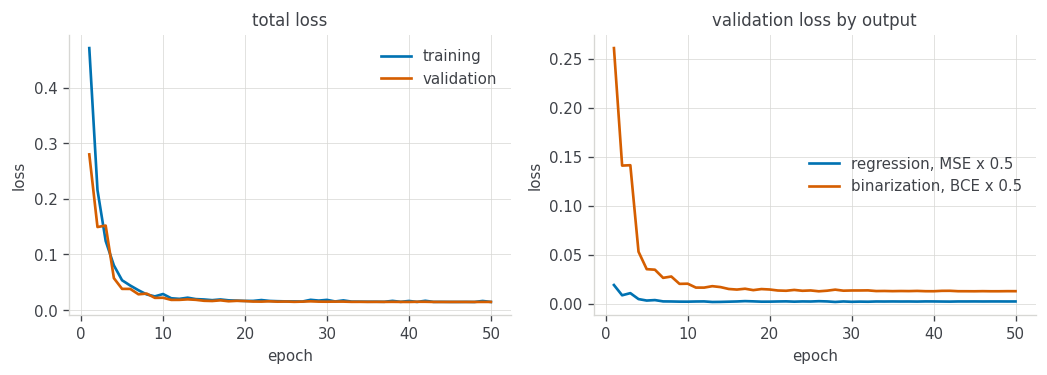

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.2))
axes[0].plot(history["epoch"], history["train_total"], color=NORMAL, label="training")
axes[0].plot(history["epoch"], history["val_total"], color=STRESS, label="validation")
axes[0].set_title("total loss")
axes[0].legend(loc="upper right")
axes[1].plot(history["epoch"], history["val_regression"], color=NORMAL, label="regression, MSE x 0.5")
axes[1].plot(history["epoch"], history["val_binarization"], color=STRESS, label="binarization, BCE x 0.5")
axes[1].set_title("validation loss by output")
axes[1].legend(loc="center right")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
fig.tight_layout()
plt.show()

## 5. Per-base prediction

The model scores a sequence once per condition: the same one-hot bases, with the condition channel at 0 and
then at 1. The sequence below was held out of the fold, so the model has not seen its targets.

In the published pipeline this step is `scripts/run_gencode_inceptis_raw_scores.py`, which runs the ten
trained folds over a transcript FASTA and writes per-base scores for every position. The README has the
commands.

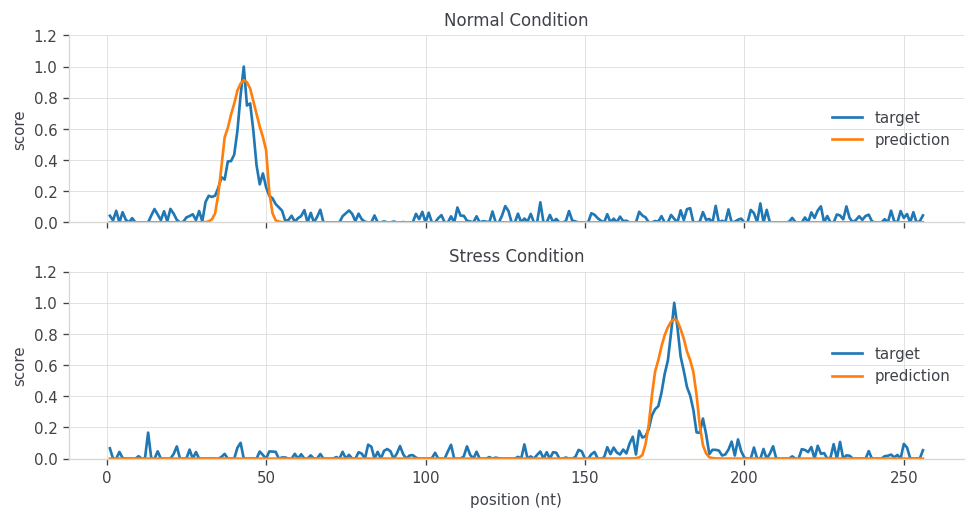

In [10]:
held_out_id = sorted(held_out_transcripts)[0]
held_out_sequence = sequences[held_out_id]
aug_site, cug_site = sites_of(held_out_id)

model.eval()
with torch.inference_mode():
    batch = np.stack([encode(held_out_sequence, 0), encode(held_out_sequence, 1)])
    scores = model(torch.from_numpy(batch).to(DEVICE))["regression"].float().cpu().numpy()

prediction = pd.DataFrame({
    "position": position,
    "normal_score": scores[0],
    "stress_score": scores[1],
    "normal_target": targets[held_out_id][0],
    "stress_target": targets[held_out_id][1],
})

fig, axes = plt.subplots(2, 1, figsize=(8.2, 4.4), sharex=True, sharey=True)

for ax, score, target, name in [
    (axes[0], "normal_score", "normal_target", "Normal Condition"),
    (axes[1], "stress_score", "stress_target", "Stress Condition")
]:
    ax.plot(prediction.position, prediction[target],
            color="tab:blue", label="target")
    ax.plot(prediction.position, prediction[score],
            color="tab:orange", label="prediction")

    ax.set_ylim(0, 1.2)
    ax.set_ylabel("score")
    ax.set_title(name)
    ax.legend(loc="center right")

axes[1].set_xlabel("position (nt)")
fig.tight_layout()
plt.show()

The two conditions pick out different sites: with the condition channel at 0 the peak sits on the TISU AUG,
with it at 1 on the bare CUG, and each site stays near zero under the other condition. That is the switch
the data were built to contain, learned from sequence on a transcript the fold never saw. It says nothing
about how the published model behaves on real transcripts.

## 6. Sequence design with IncepTIS-Evolve

IncepTIS-Evolve runs a genetic algorithm over the mutable positions of a fixed template. Every candidate is
scored under both conditions, and the objective rewards initiation at the uORF site under the normal
condition together with initiation at the reporter start under stress: an upstream ORF that holds the
reporter silent until the stress condition releases it.

```text
 population of candidate sequences        fixed segments are never mutated
              |
 score every candidate under both conditions
              |
 objective + constraints at the named sites
   uORF site    high under normal, low under stress
   reporter     low under normal, high under stress
   elsewhere    internal initiation penalised
              |
 keep elites -> tournament -> crossover -> mutation -> random immigrants
              |
 next generation                          (the published run used 600)
```

The published run designs a 1,280-nt construct with three uORFs upstream of a luciferase reporter;
`examples/translation_switch_uORF3.jsonc` holds that configuration, 1,024 candidates over 600 generations,
seed 2772, with every key documented in comments.

The demo model knows only what its training data contained: a TISU AUG between positions 40 and 70, a bare
CUG between 160 and 190, inside 256-nt sequences. Asking it about a 1,280-nt construct would be asking
about sequence it has never seen, so the configuration below states the same kind of switch inside that
geometry. One uORF position at 55, the reporter start fixed as a bare CUG at 175, and every other position
open to the search. It is written out in the cell so it can be edited here.

The package scores candidates with the published NTv3 ensemble, so the notebook puts its own scorer in that
place, backed by the model trained above. Three optional terms stay switched off: Evo2 naturalness and
Evo2-generated initial sequences (`evo2_constraint`), ExtraTrees-based proposals (`bo`), and the
RNAdegformer stability term (`stability_model`).

In [11]:
# The design task, in the geometry the demo model was trained on: one uORF position inside the
# window where the training data put its TISU AUG, and the reporter start fixed as a bare CUG
# inside the window where it put its CUG. Everything else is open to the search. Edit the search
# under "ga", the target positions under "sites", what counts as success under "success_constraints",
# and what the search rewards under the three objective blocks.
UORF_POSITION, REPORTER_POSITION = 55, 175

DESIGN_CONFIG = {
    "output_root": "outputs/design",
    "experiment_name": "demo",
    "timestamp_experiment_dir": True,
    "seed": 524,
    "length": 256,
    "models": {
        "exp038_weights_dir": "unused: the notebook scorer carries the model",
        "exp038_backbone": "InstaDeepAI/NTv3_100M_pre",
        "exp038_folds": 1,
        "device": "auto",
        "evo2_model": "evo2_1b_base",
    },
    "fixed_segments": [
        {
            "label": "reporter",
            "start": REPORTER_POSITION,
            "sequence": (
                "CTGAAAGGCCATCTATTCGGAGGTCTACAGCTCTTACTTTATCCCCCGCT"
                "TGTGCTTGTGGAGTGACTCTCTTCTAGAAGGT"
            ),
        },
    ],
    "sites": [
        {"name": "uORF1", "position": UORF_POSITION, "group": "uorf"},
        {"name": "luciferase", "position": REPORTER_POSITION, "group": "luciferase"},
    ],
    "success_constraints": {
        "normal_uorf_mean_min": 0.12,
        "normal_luciferase_max": 0.08,
        "stress_luciferase_min": 0.08,
        "stress_uorf_mean_max": 0.14,
        "luciferase_induction_min": 0.04,
        "uorf_difference_sum_min": 0.04,
        "uorf_difference_sites": ["uORF1"],
    },
    "site_constraints": [
        {"site": "uORF1", "condition": "normal", "min": 0.1},
        {"site": "luciferase", "condition": "normal", "max": 0.08},
        {"site": "luciferase", "condition": "stress", "min": 0.08},
        {"site": "luciferase", "difference": "stress_minus_normal", "min": 0.04},
    ],
    "objective_weights": {
        "desired_pair_min": 10.0,
        "normal_uorf_mean": 1.3,
        "stress_luciferase": 11.5,
        "luciferase_induction": 11.5,
        "uorf_difference_sum": 1.95,
        "normal_luciferase_penalty": 4.0,
        "stress_uorf_mean_penalty": 2.45,
        "internal_tis_penalty": 10,
    },
    "site_objectives": [
        {"site": "uORF1", "condition": "normal", "direction": "high", "weight": 1.3},
        {
            "site": "uORF1",
            "difference": "normal_minus_stress",
            "direction": "high",
            "weight": 0.65,
        },
        {"site": "luciferase", "condition": "normal", "direction": "low", "weight": 6.9},
        {
            "site": "luciferase",
            "difference": "stress_minus_normal",
            "direction": "high",
            "weight": 9.2,
        },
    ],
    "metric_target_objectives": [
        {"site": "uORF1", "condition": "normal", "min": 0.15, "weight": 16.0},
        {"site": "uORF1", "condition": "stress", "max": 0.14, "weight": 2.2},
        {"site": "luciferase", "condition": "normal", "max": 0.06, "weight": 18.4},
        {"site": "luciferase", "condition": "stress", "min": 0.12, "weight": 18.4},
    ],
    "naturalness_constraint": "none",
    "evo2_constraint": {
        "raw_baseline_n": 0,
        "sd_multiplier": -1.0,
        "initial_seed_count": 0,
        "prompt": "ACGT",
        "temperature": 1.0,
        "top_k": 4,
        "topk_per_generation": 0,
        "batch_size": 4,
        "weight": 0.0,
        "fail_penalty": 0.0,
    },
    "stability_model": {     # We implemented RNA stability model(RNAdegformer, arnie) for further evaluation of the designed sequences,
        "enabled": False,    # but it was not used in the analyses presented in the manuscript.
        "project_root": ".",
        "webapp_dir": "third_party/RNAdegformer-Webapp",   # He, Shujun, et al. "RNAdegformer: accurate prediction of mRNA degradation at nucleotide resolution with deep learning." Briefings in bioinformatics 24.1 (2023): bbac581.
        "arnie_src": "third_party/arnie/src",              # Wayment-Steele, Hannah K., et al. "Deep learning models for predicting RNA degradation via dual crowdsourcing." Nature Machine Intelligence 4.12 (2022): 1174-1184.
        "weights_dir": "model_assets/RNAdegformer-Webapp/RNA_Inference/best_weights",
        "folds": "all",
        "target_columns": ["reactivity", "deg_Mg_pH10", "deg_pH10", "deg_Mg_50C", "deg_50C"],
        "topk_per_generation": 8,
        "weight": 0.8,
        "max_mean_degradation": None,
        "fail_penalty": 1.0,
    },
    "bo": {
        "enabled": False,
        "start_generation": 20,
        "min_observations": 4096,
        "interval": 1,
        "proposals_per_generation": 128,
        "candidate_pool_size": 4096,
        "seed_elite_count": 48,
        "mutated_elite_fraction": 0.55,
        "crossover_fraction": 0.3,
        "train_max_samples": 12000,
        "n_estimators": 64,
        "max_features": "sqrt",
        "min_samples_leaf": 2,
        "bootstrap": True,
        "exploration_beta": 0.75,
        "n_jobs": -1,
    },
    "ga": {
        "population_size": 192,
        "generations": 300,
        "batch_size": 16,
        "elite_count": 4,
        "random_immigrants": 12,
        "tournament_k": 3,
        "mutation_rate": 0.035,
        "local_mutation_rate": 0.12,
        "local_mutation_radius": 8,
    },
    "gif": {
        "enabled": True,
        "top_rank": 32,
        "right_profile_count": 3,
        "fps": 8,
        "interval_ms": 120,
        "frame_step": 1,
        "point_size": 18,
        "point_alpha": 0.72,
    },
}

256 nt, 82 fixed positions, 174 mutable positions


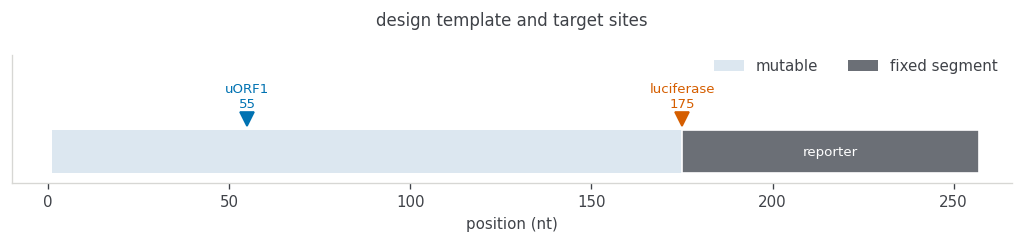

In [12]:
# The template: which positions are fixed, and where the four target sites sit.
from matplotlib.patches import Patch

from inceptis_evolve import FixedDesign

design = FixedDesign(DESIGN_CONFIG)
print(f"{design.length} nt, {int(design.fixed.sum())} fixed positions,"
      f" {len(design.mutable_positions)} mutable positions")

runs, start = [], 0
for index in range(1, design.length + 1):
    if index == design.length or design.labels[index] != design.labels[start]:
        if design.fixed[start]:
            runs.append((start + 1, index - start, design.labels[start]))
        start = index

fig, ax = plt.subplots(figsize=(8.6, 2.1))
ax.broken_barh([(1, design.length - 1)], (0.22, 0.30), facecolors="#dce7f0", edgecolor="none")
ax.broken_barh([(begin, length) for begin, length, _ in runs], (0.22, 0.30),
               facecolors=MUTED, edgecolor="white", linewidth=1.0)
for begin, length, label in runs:
    if length > 60:
        ax.text(begin + length / 2, 0.37, label.replace("_", " "), ha="center", va="center",
                color="white", fontsize=8)
for site in design.sites:
    colour = STRESS if site.get("group") == "luciferase" else NORMAL
    ax.plot([site["position"]], [0.60], marker="v", markersize=8, color=colour)
    ax.text(site["position"], 0.66, f"{site['name']}\n{site['position']}", ha="center", va="bottom",
            fontsize=8, color=colour)
ax.set_xlim(-10, design.length + 10)
ax.set_ylim(0.15, 1.05)
ax.set_yticks([])
ax.set_xlabel("position (nt)")
ax.grid(False)
ax.set_title("design template and target sites", pad=18)
ax.legend(handles=[Patch(facecolor="#dce7f0", label="mutable"),
                   Patch(facecolor=MUTED, label="fixed segment")],
          loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.08))
fig.tight_layout()
plt.show()

In [13]:
# The optimizer asks its scorer for both conditions of every candidate; this one answers with
# the model trained above instead of the published NTv3 ensemble.

import warnings
warnings.filterwarnings('ignore')

import json

import inceptis_evolve.optimizer as evolve_optimizer
from inceptis_evolve import SequenceOptimizer, create_experiment_dir, seed_everything


class DemoScorer:
    '''Drop-in replacement for the package's NTv3 scorer, with the notebook's model inside.'''

    def __init__(self, weights_dir, design, device, backbone, folds):
        self.design, self.device = design, torch.device(device)

    def predict_batch(self, candidates, batch_size):
        profiles = []
        for start in range(0, len(candidates), batch_size):
            chunk = [self.design.clean_sequence(candidate)
                     for candidate in candidates[start:start + batch_size]]
            batch = np.stack([encode(candidate, condition)
                              for candidate in chunk for condition in (0, 1)])
            with torch.inference_mode():
                values = model(torch.from_numpy(batch).to(self.device))["regression"]
            values = values.float().cpu().numpy()
            profiles.extend((values[2 * i], values[2 * i + 1]) for i in range(len(chunk)))
        return profiles


evolve_optimizer.BatchExp038Scorer = DemoScorer

# The run keeps a copy of the configuration next to its outputs.
config_path = REPO / "outputs" / "design_notebook.json"
config_path.parent.mkdir(parents=True, exist_ok=True)
config_path.write_text(json.dumps(DESIGN_CONFIG, indent=2))

model.eval()
run_dir, resolved_cfg = create_experiment_dir(DESIGN_CONFIG, config_path)
seed_everything(int(resolved_cfg.get("seed", 0)))
design_run = SequenceOptimizer(resolved_cfg)
design_summary = design_run.write_outputs(design_run.run())
print("run directory:", run_dir)
print("selected candidate:", design_summary["selected_source"],
      "| all constraints met:", design_summary["phenotype_success"])

{'generation': 0, 'best_score': 20.80944226411812, 'best_exp038_score': 20.80944226411812, 'best_evo2_mean_logprob': None, 'best_evo2_pass': False, 'best_rnadegformer_stability_score': None, 'best_rnadegformer_mean_degradation': None, 'global_best_constrained_score': nan, 'bo_proposals_from_previous_generation': 0, 'phenotype_success': False, 'normal_uorf_mean': 0.0003787843161262572, 'normal_luciferase': 0.00044874357990920544, 'stress_uorf_mean': 0.00046591070713475347, 'stress_luciferase': 0.9246394038200378, 'luciferase_induction': 0.9241906602401286, 'uorf_difference_sum': -8.712639100849628e-05, 'normal_internal_max': 0.0009114961721934378, 'stress_internal_max': 0.6559231281280518, 'normal_max': 0.0009114961721934378, 'normal_max_pos': 256, 'stress_max': 0.9246394038200378, 'stress_max_pos': 175, 'normal_uORF1': 0.0003787843161262572, 'stress_uORF1': 0.00046591070713475347, 'stress_minus_normal_uORF1': 8.712639100849628e-05, 'stress_minus_normal_luciferase': 0.9241906404495239, 

Each run writes its own directory under `outputs/design/`:

| Output | Contents |
| --- | --- |
| `run_inputs/` | the configuration and its resolved copy |
| `best_sequence.fa`, `best_sequence_predictions.csv` | the selected sequence and its per-base predictions |
| `ga_history.csv`, `ga_population_scores.csv` | best candidate per generation; every candidate of every generation |
| `ga_best_profiles.csv`, `ga_top_profiles.csv` | prediction profiles of the best and the top candidates |
| `summary.json` | selected sequence, constraint status, site predictions |
| `top_candidates_with_profile.gif`, `top_candidates_with_profile_final.png` | the search, written when `gif.enabled` is set |

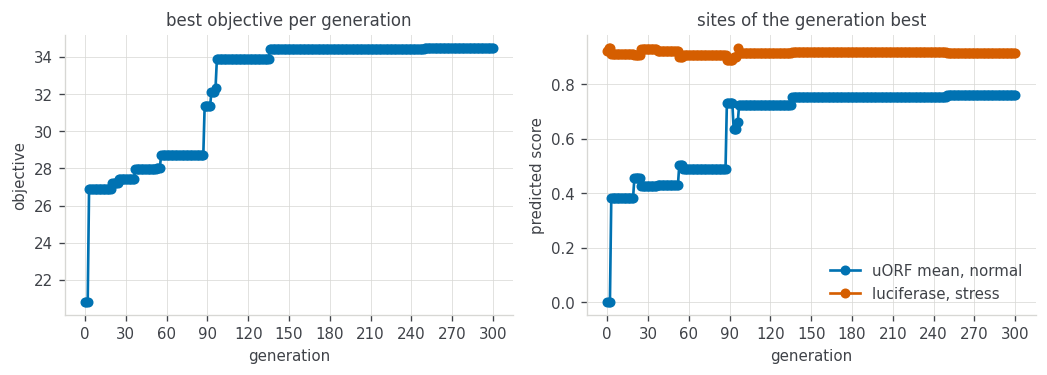

In [14]:
# How the search moved, generation by generation.
ga = pd.read_csv(run_dir / "ga_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.2))
axes[0].plot(ga["generation"], ga["best_score"], color=NORMAL, marker="o", markersize=5)
axes[0].set_title("best objective per generation")
axes[0].set_ylabel("objective")
axes[1].plot(ga["generation"], ga["normal_uorf_mean"], color=NORMAL, marker="o", markersize=5,
             label="uORF mean, normal")
axes[1].plot(ga["generation"], ga["stress_luciferase"], color=STRESS, marker="o", markersize=5,
             label="luciferase, stress")
axes[1].set_title("sites of the generation best")
axes[1].set_ylabel("predicted score")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("generation")
    ax.set_xticks(ga["generation"][::max(1, len(ga) // 10)])
fig.tight_layout()
plt.show()

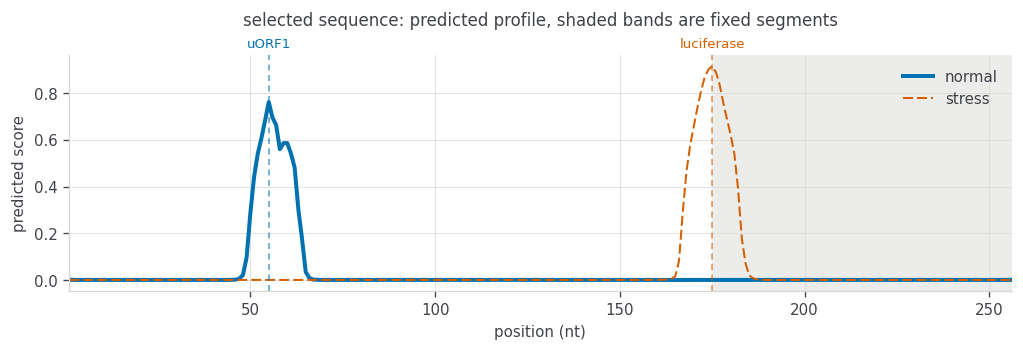

In [15]:
# The selected sequence, scored base by base under both conditions.
best = pd.read_csv(run_dir / "best_sequence_predictions.csv")

fig, ax = plt.subplots(figsize=(8.6, 3.0))
for begin, length, label in runs:
    ax.axvspan(begin, begin + length, color=GRID, alpha=0.45, linewidth=0)
ax.plot(best["position_1based"], best["prediction_normal"], color=NORMAL, linewidth=2.4, label="normal")
ax.plot(best["position_1based"], best["prediction_stress"], color=STRESS, linewidth=1.2,
        linestyle=(0, (5, 2)), label="stress")
for site in design.sites:
    colour = STRESS if site.get("group") == "luciferase" else NORMAL
    ax.axvline(site["position"], color=colour, linestyle=(0, (4, 3)), linewidth=0.9, alpha=0.7)
    ax.annotate(site["name"], xy=(site["position"], 1.02), xycoords=("data", "axes fraction"),
                ha="center", va="bottom", fontsize=8, color=colour)
ax.set_xlim(1, design.length)
ax.set_xlabel("position (nt)")
ax.set_ylabel("predicted score")
ax.set_title("selected sequence: predicted profile, shaded bands are fixed segments", pad=18)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

The search has one thing to build: a TISU element at the uORF position, the only way the demo model raises
the normal-condition score anywhere. That is a needle to thread, because the model gives almost nothing for
a partial element, so the population spends generations drawing random sequence at that position until one
candidate lands close enough for selection to finish the job. The reporter start is a fixed CUG and already
scores under stress from the first generation. The internal-initiation penalty argues against stray CUGs
elsewhere, though at the weights of the published configuration it does not clear them all. None of these
numbers describe the published model, which was trained on measured initiation data.

### The search, frame by frame

The run writes the animation itself. On the left, the top candidates of each generation sit in the plane of
the two headline metrics: the mean predicted uORF score under the normal condition against the predicted
luciferase score under stress. A star marks the best candidate of that generation, and a black ring marks
candidates that meet every constraint. On the right are the per-base profiles of the three best candidates
of the same generation, with the uORF sites and the luciferase start marked.

A population of 96 over 50 generations is still a small search next to the published run, which carried
1,024 candidates through 600 generations. The last frame is also saved as a PNG next to the GIF.

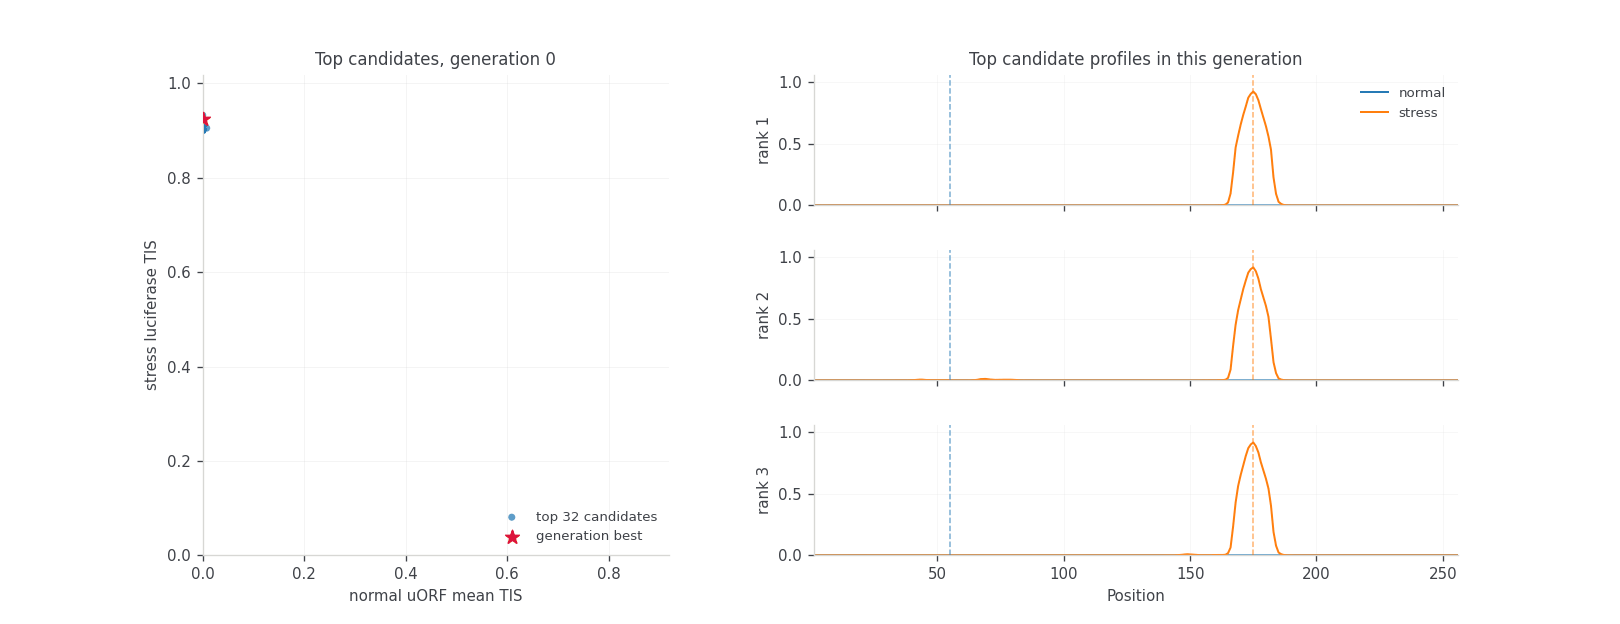

In [16]:
from IPython.display import Image

Image(filename=str(run_dir / "top_candidates_with_profile.gif"))